# Comparing PPO, REINFORCE, and One-Step Actor-Critic

This notebook applies PPO to the five Gymnasium environments used in
the previous assignment: CartPole, Acrobot, MountainCar, FrozenLake,
and Blackjack.

PPO is first developed and checked on CartPole, then applied to the
other four environments. Each environment has a comparison plot showing
episode total reward for all three algorithms, averaged across runs.

In [25]:
import gymnasium as gym
import torch

from gymnasium.spaces.utils import flatdim, flatten
from torch import nn
from torch.distributions import Categorical

ENV_IDS = [
    "CartPole-v1",
    "Acrobot-v1",
    "MountainCar-v0",
    "FrozenLake-v1",
    "Blackjack-v1",
]

In [26]:
def encode_state(observation, observation_space):
    encoded = flatten(observation_space, observation)
    return torch.as_tensor(encoded, dtype=torch.float32)


class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
        )

    def forward(self, state):
        return self.net(state)


class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )

    def forward(self, state):
        return self.net(state).squeeze(-1)

## Experimental Setup

The baseline curves use saved REINFORCE and One-step Actor-Critic
rewards from the previous assignment. Each main run uses 300
completed episodes with seeds 1–5.

PPO collects up to 128 transitions per rollout and performs four
update epochs with mini-batches of up to 64 transitions. It uses
gamma = 0.99, GAE lambda = 0.95, and a clipping parameter of 0.2.
The Adam learning rates are 0.0003 for the policy and 0.001 for
the value network.

In [27]:
env = gym.make("CartPole-v1")

try:
    observation, _ = env.reset(seed=0)
    state = encode_state(observation, env.observation_space)

    state_dim = flatdim(env.observation_space)
    action_dim = env.action_space.n

    policy = PolicyNetwork(state_dim, action_dim)
    value_network = ValueNetwork(state_dim)

    with torch.no_grad():
        logits = policy(state)
        value = value_network(state)

    print("State shape:", tuple(state.shape))
    print("Policy logits shape:", tuple(logits.shape))
    print("Value shape:", tuple(value.shape))

finally:
    env.close()

State shape: (4,)
Policy logits shape: (2,)
Value shape: ()


## PPO Rollout Collection

Collect a fixed number of transitions using the current policy.
Store the encoded states, sampled actions, old action log probabilities,
value estimates, rewards, and episode-end flags.

A rollout can contain several episodes or end partway through an episode.
Carry the current observation and unfinished episode reward into the
next rollout. Record total rewards only for completed episodes.

As in the previous assignment, the environment's time limit defines
the end of the finite episode.

In [28]:
@torch.no_grad()
def collect_ppo_rollout(
    env,
    policy,
    value_network,
    observation,
    episode_reward=0.0,
    num_steps=128,
    max_completed_episodes=None,
):
    states = []
    actions = []
    old_log_probs = []
    values = []
    rewards = []
    episode_ends = []
    completed_rewards = []

    for _ in range(num_steps):
        state = encode_state(observation, env.observation_space)
        distribution = Categorical(logits=policy(state))
        action = distribution.sample()

        next_observation, reward, terminated, truncated, _ = env.step(
            action.item()
        )
        episode_ended = terminated or truncated

        states.append(state)
        actions.append(action)
        old_log_probs.append(distribution.log_prob(action))
        values.append(value_network(state))
        rewards.append(float(reward))
        episode_ends.append(episode_ended)

        episode_reward += float(reward)
        observation = next_observation

        if episode_ended:
            completed_rewards.append(episode_reward)
            observation, _ = env.reset()
            episode_reward = 0.0

            if (
                max_completed_episodes is not None
                and len(completed_rewards) >= max_completed_episodes
            ):
                break

    # Estimate the value just beyond the rollout boundary.
    last_state = encode_state(observation, env.observation_space)

    rollout = {
        "states": torch.stack(states),
        "actions": torch.stack(actions),
        "old_log_probs": torch.stack(old_log_probs),
        "values": torch.stack(values),
        "rewards": torch.tensor(rewards, dtype=torch.float32),
        "episode_ends": torch.tensor(episode_ends, dtype=torch.bool),
        "last_value": value_network(last_state),
    }

    return rollout, observation, episode_reward, completed_rewards

In [29]:
env = gym.make("CartPole-v1")

try:
    observation, _ = env.reset(seed=0)

    rollout, next_observation, partial_reward, completed_rewards = (
        collect_ppo_rollout(
            env=env,
            policy=policy,
            value_network=value_network,
            observation=observation,
            num_steps=128,
            max_completed_episodes=None,
        )
    )

    print("States shape:", tuple(rollout["states"].shape))
    print("Actions shape:", tuple(rollout["actions"].shape))
    print("Old log probabilities shape:", tuple(rollout["old_log_probs"].shape))
    print("Old log probabilities require gradients:",
          rollout["old_log_probs"].requires_grad)
    print("Completed episode rewards:", completed_rewards)
    print("Unfinished episode reward:", partial_reward)

finally:
    env.close()

States shape: (128, 4)
Actions shape: (128,)
Old log probabilities shape: (128,)
Old log probabilities require gradients: False
Completed episode rewards: [25.0, 21.0, 13.0, 10.0, 19.0, 17.0, 9.0]
Unfinished episode reward: 14.0


## Generalized Advantage Estimation

Compute the TD error and advantage backward through the rollout.

$$
\delta_t = r_t + \gamma m_t V_{t+1} - V_t
$$

$$
\hat A_t = \delta_t + \gamma \lambda m_t \hat A_{t+1}
$$

The mask $m_t$ is zero when the transition ends the episode and one
otherwise. If the rollout ends mid-episode, use the stored value
estimate of the next observation to compute the final TD error.

The value target is the advantage plus the original value estimate.

$$
V_t^{\mathrm{target}} = \hat A_t + V_t
$$

In [30]:
@torch.no_grad()
def compute_gae(rollout, gamma=0.99, gae_lambda=0.95):
    rewards = rollout["rewards"]
    values = rollout["values"]
    episode_ends = rollout["episode_ends"]

    advantages = torch.zeros_like(values)
    running_advantage = torch.zeros_like(rollout["last_value"])
    next_value = rollout["last_value"]

    for t in reversed(range(len(rewards))):
        continuation = (~episode_ends[t]).to(dtype=values.dtype)

        td_error = rewards[t] + gamma * continuation * next_value - values[t]
        running_advantage = (
            td_error + gamma * gae_lambda * continuation * running_advantage
        )

        advantages[t] = running_advantage
        next_value = values[t]

    value_targets = advantages + values
    return advantages, value_targets


advantages, value_targets = compute_gae(rollout)

print("Advantages shape:", tuple(advantages.shape))
print("Value targets shape:", tuple(value_targets.shape))
print("Advantages are finite:", torch.isfinite(advantages).all().item())
print("Value targets are finite:", torch.isfinite(value_targets).all().item())

episode_ends = rollout["episode_ends"]
print(
    "Targets at episode ends match rewards:",
    torch.allclose(value_targets[episode_ends], rollout["rewards"][episode_ends]),
)

Advantages shape: (128,)
Value targets shape: (128,)
Advantages are finite: True
Value targets are finite: True
Targets at episode ends match rewards: True


## PPO Clipped Policy Loss

Recompute the log probability of each sampled action under the current
policy. The probability ratio compares it with the log probability
stored during rollout collection.

$$
r_t = \exp(\log \pi_\theta(a_t \mid s_t)
            - \log \pi_{\mathrm{old}}(a_t \mid s_t))
$$

Compute the clipped and unclipped objectives for each transition.
Take the smaller objective before averaging. Negate the result so that
minimizing the loss maximizes the clipped surrogate objective.

$$
L_{\mathrm{policy}} =
-\operatorname{mean}_t
\left[
\min\left(r_t \hat A_t,
\operatorname{clip}(r_t, 1-\epsilon, 1+\epsilon)\hat A_t\right)
\right]
$$

In [31]:
def ppo_policy_loss(
    policy,
    states,
    actions,
    old_log_probs,
    advantages,
    clip_epsilon=0.2,
):
    distribution = Categorical(logits=policy(states))
    new_log_probs = distribution.log_prob(actions)

    ratios = torch.exp(new_log_probs - old_log_probs)
    clipped_ratios = torch.clamp(
        ratios,
        min=1.0 - clip_epsilon,
        max=1.0 + clip_epsilon,
    )

    unclipped_objective = ratios * advantages
    clipped_objective = clipped_ratios * advantages

    policy_loss = -torch.minimum(
        unclipped_objective, clipped_objective
    ).mean()

    return policy_loss, ratios

In [32]:
policy_loss, ratios = ppo_policy_loss(
    policy=policy,
    states=rollout["states"],
    actions=rollout["actions"],
    old_log_probs=rollout["old_log_probs"],
    advantages=advantages,
)

print("Ratios shape:", tuple(ratios.shape))
print(
    "Ratios are close to one:",
    torch.allclose(ratios, torch.ones_like(ratios), atol=1e-6),
)
print("Policy loss:", policy_loss.item())
print("Policy loss requires gradients:", policy_loss.requires_grad)

Ratios shape: (128,)
Ratios are close to one: True
Policy loss: -6.836573600769043
Policy loss requires gradients: True


## PPO Updates with Mini-batches

Normalize the advantages once across the rollout for the policy update.
Keep the value targets computed from the original advantages.

Shuffle the rollout at the start of each update epoch. For each
mini-batch, update the policy using the clipped objective and train
the value network using mean squared error against the value targets.

The old action log probabilities and value targets are fixed throughout
the update. Recompute the current policy probabilities and value
predictions for each mini-batch.

In [33]:
def update_ppo(
    policy,
    value_network,
    policy_optimizer,
    value_optimizer,
    rollout,
    advantages,
    value_targets,
    update_epochs=4,
    minibatch_size=64,
    clip_epsilon=0.2,
):
    normalized_advantages = (
        (advantages - advantages.mean())
        / (advantages.std(unbiased=False) + 1e-8)
    )

    num_samples = len(rollout["actions"])
    policy_losses = []
    value_losses = []

    for _ in range(update_epochs):
        shuffled_indices = torch.randperm(num_samples)

        for indices in shuffled_indices.split(minibatch_size):
            states = rollout["states"][indices]

            policy_loss, _ = ppo_policy_loss(
                policy=policy,
                states=states,
                actions=rollout["actions"][indices],
                old_log_probs=rollout["old_log_probs"][indices],
                advantages=normalized_advantages[indices],
                clip_epsilon=clip_epsilon,
            )

            policy_optimizer.zero_grad()
            policy_loss.backward()
            policy_optimizer.step()

            predicted_values = value_network(states)
            value_loss = (predicted_values - value_targets[indices]).square().mean()

            value_optimizer.zero_grad()
            value_loss.backward()
            value_optimizer.step()

            policy_losses.append(policy_loss.item())
            value_losses.append(value_loss.item())

    return {
        "minibatch_updates": len(policy_losses),
        "mean_policy_loss": sum(policy_losses) / len(policy_losses),
        "mean_value_loss": sum(value_losses) / len(value_losses),
    }

In [34]:
policy_optimizer = torch.optim.Adam(policy.parameters(), lr=3e-4)
value_optimizer = torch.optim.Adam(value_network.parameters(), lr=1e-3)

policy_before = next(policy.parameters()).detach().clone()
value_before = next(value_network.parameters()).detach().clone()

update_stats = update_ppo(
    policy=policy,
    value_network=value_network,
    policy_optimizer=policy_optimizer,
    value_optimizer=value_optimizer,
    rollout=rollout,
    advantages=advantages,
    value_targets=value_targets,
)

print("Mini-batch updates:", update_stats["minibatch_updates"])
print("Mean policy loss:", update_stats["mean_policy_loss"])
print("Mean value loss:", update_stats["mean_value_loss"])
print(
    "Policy weights changed:",
    not torch.equal(policy_before, next(policy.parameters()).detach()),
)
print(
    "Value weights changed:",
    not torch.equal(value_before, next(value_network.parameters()).detach()),
)

Mini-batch updates: 8
Mean policy loss: -0.005558370146900415
Mean value loss: 56.74203586578369
Policy weights changed: True
Value weights changed: True


## PPO Training on CartPole

Initialize a fresh policy, value network, and their optimizers.
Alternate between collecting a rollout, computing GAE and value
targets, and updating both networks over four mini-batch epochs.

Collect up to 128 transitions per rollout. Carry any unfinished
episode into the next rollout and stop collection after exactly
300 completed episodes.

Record the undiscounted total reward of each completed episode.
The initial experiment uses seed 0. The number of environment
transitions depends on the lengths of the completed episodes.

In [35]:
import numpy as np


def train_ppo(env_id, num_episodes=300, seed=0, rollout_steps=128):
    torch.manual_seed(seed)
    env = gym.make(env_id)

    try:
        state_dim = flatdim(env.observation_space)
        action_dim = env.action_space.n

        policy = PolicyNetwork(state_dim, action_dim)
        value_network = ValueNetwork(state_dim)
        policy_optimizer = torch.optim.Adam(policy.parameters(), lr=3e-4)
        value_optimizer = torch.optim.Adam(value_network.parameters(), lr=1e-3)

        observation, _ = env.reset(seed=seed)
        partial_reward = 0.0
        episode_rewards = []
        next_report = 50

        while len(episode_rewards) < num_episodes:
            episodes_remaining = num_episodes - len(episode_rewards)

            rollout, observation, partial_reward, completed_rewards = (
                collect_ppo_rollout(
                    env=env,
                    policy=policy,
                    value_network=value_network,
                    observation=observation,
                    episode_reward=partial_reward,
                    num_steps=rollout_steps,
                    max_completed_episodes=episodes_remaining,
                )
            )

            advantages, value_targets = compute_gae(
                rollout, gamma=0.99, gae_lambda=0.95
            )

            update_ppo(
                policy=policy,
                value_network=value_network,
                policy_optimizer=policy_optimizer,
                value_optimizer=value_optimizer,
                rollout=rollout,
                advantages=advantages,
                value_targets=value_targets,
            )

            episode_rewards.extend(completed_rewards)

            while len(episode_rewards) >= next_report:
                recent_mean = np.mean(
                    episode_rewards[next_report - 50 : next_report]
                )
                print(
                    f"Episode {next_report}/{num_episodes} | "
                    f"Mean reward over last 50 episodes: {recent_mean:.2f}"
                )
                next_report += 50

    finally:
        env.close()

    return np.asarray(episode_rewards, dtype=np.float32)

In [36]:
ppo_cartpole_rewards = train_ppo(
    env_id="CartPole-v1",
    num_episodes=300,
    seed=0,
)

assert ppo_cartpole_rewards.shape == (300,)
assert np.isfinite(ppo_cartpole_rewards).all()

print("\nRecorded episodes:", len(ppo_cartpole_rewards))
print(f"Mean reward over first 50: {ppo_cartpole_rewards[:50].mean():.2f}")
print(f"Mean reward over last 50: {ppo_cartpole_rewards[-50:].mean():.2f}")

Episode 50/300 | Mean reward over last 50 episodes: 25.06
Episode 100/300 | Mean reward over last 50 episodes: 31.68
Episode 150/300 | Mean reward over last 50 episodes: 43.42
Episode 200/300 | Mean reward over last 50 episodes: 67.28
Episode 250/300 | Mean reward over last 50 episodes: 134.44
Episode 300/300 | Mean reward over last 50 episodes: 191.32

Recorded episodes: 300
Mean reward over first 50: 25.06
Mean reward over last 50: 191.32


## CartPole Comparison Across Five Seeds

Use seeds 1–5 and 300 episodes per run to match the episode
budget of the previous CartPole experiments.

Each run starts with fresh networks and optimizers. Store the
episode total rewards in an array with one row per seed and
one column per episode. Seed 0 is reported separately as the
preliminary run.

In [37]:
SEEDS = [1, 2, 3, 4, 5]
NUM_EPISODES = 300

def run_ppo_seeds(env_id, seeds, num_episodes):
    runs = []

    for seed in seeds:
        print(f"\n{env_id} | PPO | Seed {seed}")
        rewards = train_ppo(
            env_id=env_id,
            num_episodes=num_episodes,
            seed=seed,
        )
        runs.append(rewards)

    return np.stack(runs)


ppo_results = {}
ppo_results["CartPole-v1"] = run_ppo_seeds(
    env_id="CartPole-v1",
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
)

cartpole_runs = ppo_results["CartPole-v1"]
final_means = cartpole_runs[:, -50:].mean(axis=1)

print("\nResult shape:", cartpole_runs.shape)
print("Final 50-episode means by seed:", np.round(final_means, 2))
print(f"Mean across seeds: {final_means.mean():.3f}")


CartPole-v1 | PPO | Seed 1
Episode 50/300 | Mean reward over last 50 episodes: 31.82
Episode 100/300 | Mean reward over last 50 episodes: 40.32
Episode 150/300 | Mean reward over last 50 episodes: 45.28
Episode 200/300 | Mean reward over last 50 episodes: 123.50
Episode 250/300 | Mean reward over last 50 episodes: 205.98
Episode 300/300 | Mean reward over last 50 episodes: 275.98

CartPole-v1 | PPO | Seed 2
Episode 50/300 | Mean reward over last 50 episodes: 27.20
Episode 100/300 | Mean reward over last 50 episodes: 34.74
Episode 150/300 | Mean reward over last 50 episodes: 54.16
Episode 200/300 | Mean reward over last 50 episodes: 107.98
Episode 250/300 | Mean reward over last 50 episodes: 165.92
Episode 300/300 | Mean reward over last 50 episodes: 218.04

CartPole-v1 | PPO | Seed 3
Episode 50/300 | Mean reward over last 50 episodes: 28.48
Episode 100/300 | Mean reward over last 50 episodes: 43.30
Episode 150/300 | Mean reward over last 50 episodes: 68.50
Episode 200/300 | Mean rewar

## CartPole Comparison with Previous Algorithms

Compare PPO with REINFORCE and One-step Actor-Critic using the
episode rewards from five runs of 300 episodes each.

Average the reward at each episode index across the five seeds.
The horizontal axis measures completed episodes. The number of
environment transitions can vary with episode length.

REINFORCE: 75.304
One-step Actor-Critic: 94.944
PPO: 221.496


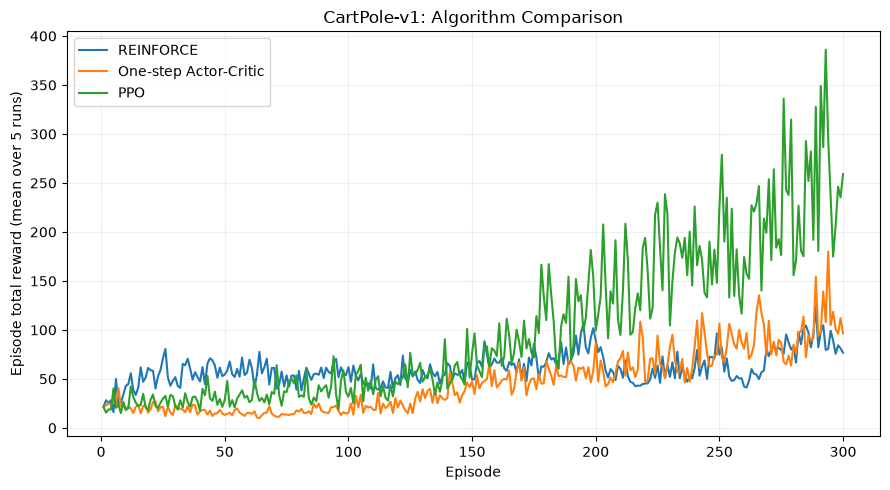

In [38]:
from pathlib import Path
import numpy as np

import matplotlib.pyplot as plt

baseline_path = Path("previous_baselines.npz")

with np.load(baseline_path, allow_pickle=False) as archive:
    baseline_rewards = {key: archive[key] for key in archive.files}

cartpole_comparison = {
    "REINFORCE": baseline_rewards["CartPole-v1__REINFORCE"],
    "One-step Actor-Critic": baseline_rewards[
        "CartPole-v1__One-step Actor-Critic"
    ],
    "PPO": ppo_results["CartPole-v1"],
}

episodes = np.arange(1, NUM_EPISODES + 1)
fig, ax = plt.subplots(figsize=(9, 5))

for algorithm, runs in cartpole_comparison.items():
    assert runs.shape == (len(SEEDS), NUM_EPISODES)
    ax.plot(episodes, runs.mean(axis=0), label=algorithm)
    print(f"{algorithm}: {runs[:, -50:].mean():.3f}")

ax.set_title("CartPole-v1: Algorithm Comparison")
ax.set_xlabel("Episode")
ax.set_ylabel("Episode total reward (mean over 5 runs)")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Acrobot Experiment

Train PPO on Acrobot using five seeds and 300 episodes per seed.
Compare its episode rewards with the saved REINFORCE and One-step
Actor-Critic results from the previous assignment.

Average rewards across seeds at each episode index. Report the mean
reward over the final 50 episodes for each algorithm.

In [39]:
def plot_algorithm_comparison(env_id, ppo_runs, baseline_rewards):
    comparison = {
        "REINFORCE": baseline_rewards[f"{env_id}__REINFORCE"],
        "One-step Actor-Critic": baseline_rewards[
            f"{env_id}__One-step Actor-Critic"
        ],
        "PPO": ppo_runs,
    }

    num_runs, num_episodes = ppo_runs.shape
    episodes = np.arange(1, num_episodes + 1)
    fig, ax = plt.subplots(figsize=(9, 5))

    print(f"\n{env_id} | Mean reward over the final 50 episodes")

    for algorithm, runs in comparison.items():
        assert runs.shape == ppo_runs.shape, f"Unexpected shape for {algorithm}"
        ax.plot(episodes, runs.mean(axis=0), label=algorithm)
        print(f"{algorithm}: {runs[:, -50:].mean():.3f}")

    ax.set_title(f"{env_id}: Algorithm Comparison")
    ax.set_xlabel("Episode")
    ax.set_ylabel(f"Episode total reward (mean over {num_runs} runs)")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()


Acrobot-v1 | PPO | Seed 1
Episode 50/300 | Mean reward over last 50 episodes: -450.92
Episode 100/300 | Mean reward over last 50 episodes: -149.24
Episode 150/300 | Mean reward over last 50 episodes: -108.46
Episode 200/300 | Mean reward over last 50 episodes: -97.54
Episode 250/300 | Mean reward over last 50 episodes: -93.06
Episode 300/300 | Mean reward over last 50 episodes: -92.18

Acrobot-v1 | PPO | Seed 2
Episode 50/300 | Mean reward over last 50 episodes: -426.64
Episode 100/300 | Mean reward over last 50 episodes: -154.64
Episode 150/300 | Mean reward over last 50 episodes: -110.88
Episode 200/300 | Mean reward over last 50 episodes: -97.44
Episode 250/300 | Mean reward over last 50 episodes: -92.16
Episode 300/300 | Mean reward over last 50 episodes: -95.52

Acrobot-v1 | PPO | Seed 3
Episode 50/300 | Mean reward over last 50 episodes: -231.70
Episode 100/300 | Mean reward over last 50 episodes: -133.70
Episode 150/300 | Mean reward over last 50 episodes: -109.34
Episode 200/3

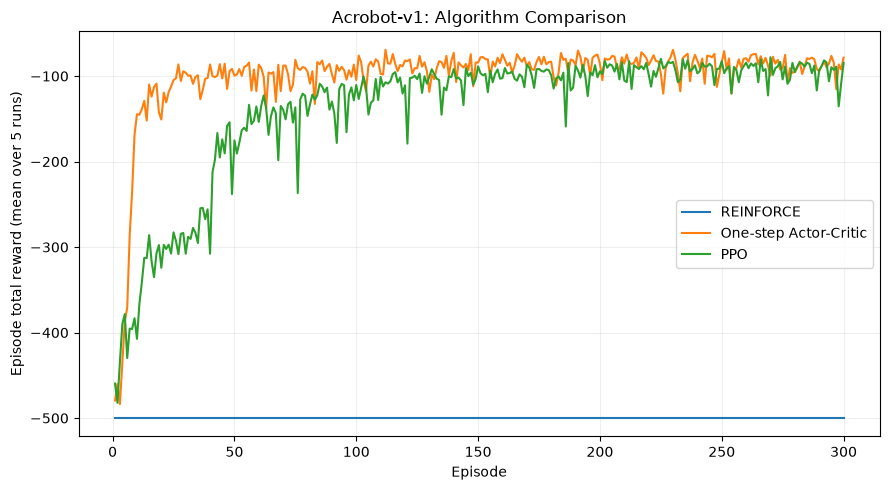

In [40]:
env_id = "Acrobot-v1"

for algorithm in ("REINFORCE", "One-step Actor-Critic"):
    key = f"{env_id}__{algorithm}"
    assert key in baseline_rewards, f"Missing baseline array: {key}"

ppo_results[env_id] = run_ppo_seeds(
    env_id=env_id,
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
)

plot_algorithm_comparison(env_id, ppo_results[env_id], baseline_rewards)

## MountainCar Experiment

Train PPO on MountainCar using five seeds and 300 episodes per seed.
Compare its learning curve with the saved REINFORCE and One-step
Actor-Critic curves.

Report the mean reward over the final 50 episodes. Also count PPO
episodes with rewards above -200 to check for completion before the
200-step limit.


MountainCar-v0 | PPO | Seed 1
Episode 50/300 | Mean reward over last 50 episodes: -200.00
Episode 100/300 | Mean reward over last 50 episodes: -200.00
Episode 150/300 | Mean reward over last 50 episodes: -200.00
Episode 200/300 | Mean reward over last 50 episodes: -200.00
Episode 250/300 | Mean reward over last 50 episodes: -200.00
Episode 300/300 | Mean reward over last 50 episodes: -200.00

MountainCar-v0 | PPO | Seed 2
Episode 50/300 | Mean reward over last 50 episodes: -200.00
Episode 100/300 | Mean reward over last 50 episodes: -200.00
Episode 150/300 | Mean reward over last 50 episodes: -200.00
Episode 200/300 | Mean reward over last 50 episodes: -200.00
Episode 250/300 | Mean reward over last 50 episodes: -200.00
Episode 300/300 | Mean reward over last 50 episodes: -200.00

MountainCar-v0 | PPO | Seed 3
Episode 50/300 | Mean reward over last 50 episodes: -200.00
Episode 100/300 | Mean reward over last 50 episodes: -200.00
Episode 150/300 | Mean reward over last 50 episodes: -20

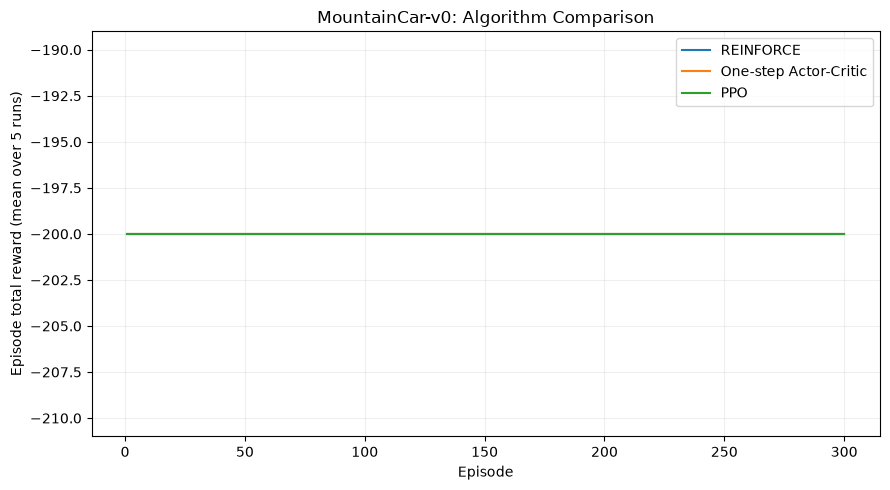

Best PPO episode reward: -200.0
PPO episodes with reward above -200: 0 out of 1500


In [41]:
env_id = "MountainCar-v0"

for algorithm in ("REINFORCE", "One-step Actor-Critic"):
    key = f"{env_id}__{algorithm}"
    assert key in baseline_rewards, f"Missing baseline array: {key}"

ppo_results[env_id] = run_ppo_seeds(
    env_id=env_id,
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
)

ppo_runs = ppo_results[env_id]
plot_algorithm_comparison(env_id, ppo_runs, baseline_rewards)

print(f"Best PPO episode reward: {ppo_runs.max():.1f}")
print(
    "PPO episodes with reward above -200:",
    np.count_nonzero(ppo_runs > -200),
    "out of",
    ppo_runs.size,
)

### MountainCar Results

All three learning curves overlap at -200. Across five seeds,
none of the 1,500 PPO episodes finished before the 200-step limit.
The three algorithms showed no improvement in episode return under
the tested settings.

## FrozenLake Experiment

Train PPO on the default FrozenLake environment using five seeds
and 300 episodes per seed. Compare the episode rewards with the
saved REINFORCE and One-step Actor-Critic results.

Reaching the goal gives an episode reward of 1. Report the mean
reward over the final 50 episodes as a success rate.


FrozenLake-v1 | PPO | Seed 1
Episode 50/300 | Mean reward over last 50 episodes: 0.02
Episode 100/300 | Mean reward over last 50 episodes: 0.00
Episode 150/300 | Mean reward over last 50 episodes: 0.00
Episode 200/300 | Mean reward over last 50 episodes: 0.02
Episode 250/300 | Mean reward over last 50 episodes: 0.04
Episode 300/300 | Mean reward over last 50 episodes: 0.04

FrozenLake-v1 | PPO | Seed 2
Episode 50/300 | Mean reward over last 50 episodes: 0.02
Episode 100/300 | Mean reward over last 50 episodes: 0.02
Episode 150/300 | Mean reward over last 50 episodes: 0.04
Episode 200/300 | Mean reward over last 50 episodes: 0.00
Episode 250/300 | Mean reward over last 50 episodes: 0.04
Episode 300/300 | Mean reward over last 50 episodes: 0.00

FrozenLake-v1 | PPO | Seed 3
Episode 50/300 | Mean reward over last 50 episodes: 0.00
Episode 100/300 | Mean reward over last 50 episodes: 0.02
Episode 150/300 | Mean reward over last 50 episodes: 0.00
Episode 200/300 | Mean reward over last 50 

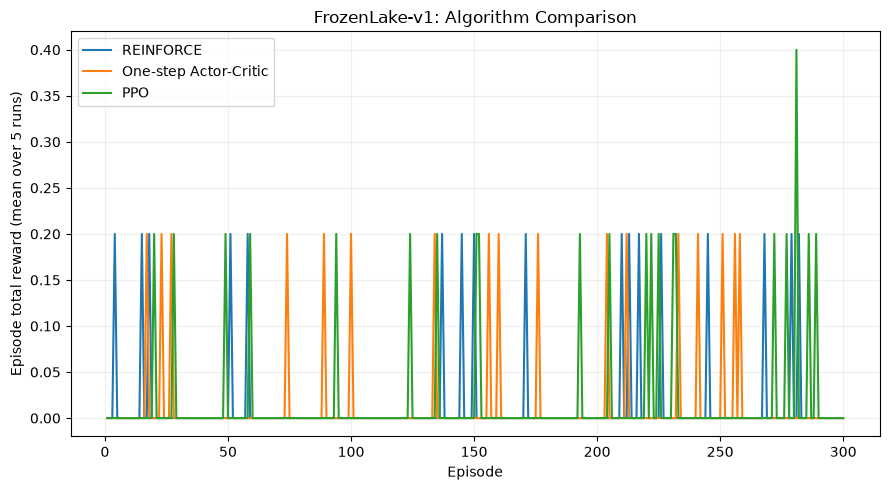

PPO success rate over the final 50 episodes: 2.4%


In [42]:
env_id = "FrozenLake-v1"

for algorithm in ("REINFORCE", "One-step Actor-Critic"):
    key = f"{env_id}__{algorithm}"
    assert key in baseline_rewards, f"Missing baseline array: {key}"

ppo_results[env_id] = run_ppo_seeds(
    env_id=env_id,
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
)

ppo_runs = ppo_results[env_id]
plot_algorithm_comparison(env_id, ppo_runs, baseline_rewards)

final_ppo_success_rate = ppo_runs[:, -50:].mean()
print(f"PPO success rate over the final 50 episodes: {final_ppo_success_rate:.1%}")

### FrozenLake Results

Across the final 50 episodes of each of the five runs, PPO reached
the goal in 6 of 250 episodes (2.4%). REINFORCE and One-step
Actor-Critic each reached the goal in 3 of 250 episodes (1.2%).

Successes were rare across all three algorithms. The observed
difference is too small to establish a reliable advantage for PPO.

## Blackjack Experiment

Train PPO on Blackjack using five seeds and 300 episodes per seed.
Compare its learning curve and final 50-episode mean reward with
the saved REINFORCE and One-step Actor-Critic results.

Episode rewards are +1 for a win, 0 for a draw, and -1 for a loss.
The mean reward measures net outcome per episode.


Blackjack-v1 | PPO | Seed 1
Episode 50/300 | Mean reward over last 50 episodes: -0.40
Episode 100/300 | Mean reward over last 50 episodes: -0.20
Episode 150/300 | Mean reward over last 50 episodes: -0.36
Episode 200/300 | Mean reward over last 50 episodes: -0.56
Episode 250/300 | Mean reward over last 50 episodes: -0.40
Episode 300/300 | Mean reward over last 50 episodes: -0.16

Blackjack-v1 | PPO | Seed 2
Episode 50/300 | Mean reward over last 50 episodes: -0.36
Episode 100/300 | Mean reward over last 50 episodes: -0.68
Episode 150/300 | Mean reward over last 50 episodes: -0.66
Episode 200/300 | Mean reward over last 50 episodes: -0.42
Episode 250/300 | Mean reward over last 50 episodes: -0.28
Episode 300/300 | Mean reward over last 50 episodes: -0.50

Blackjack-v1 | PPO | Seed 3
Episode 50/300 | Mean reward over last 50 episodes: -0.56
Episode 100/300 | Mean reward over last 50 episodes: -0.28
Episode 150/300 | Mean reward over last 50 episodes: -0.26
Episode 200/300 | Mean reward o

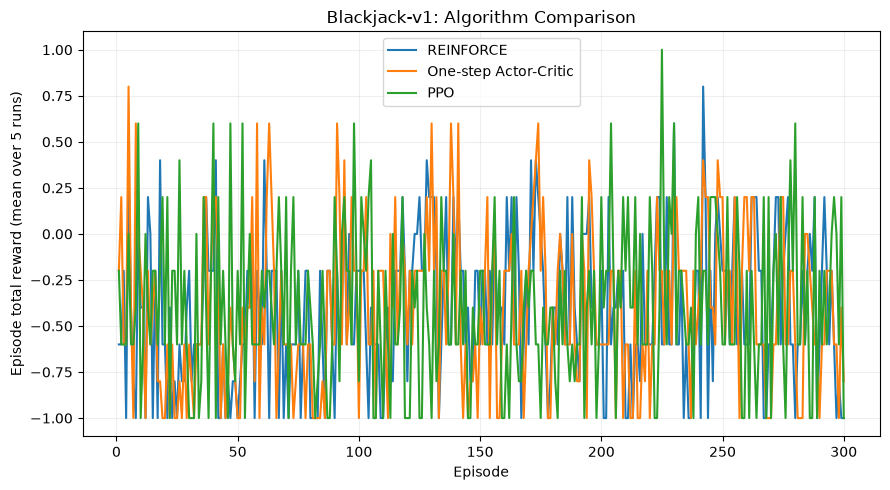

In [43]:
env_id = "Blackjack-v1"

for algorithm in ("REINFORCE", "One-step Actor-Critic"):
    key = f"{env_id}__{algorithm}"
    assert key in baseline_rewards, f"Missing baseline array: {key}"

ppo_results[env_id] = run_ppo_seeds(
    env_id=env_id,
    seeds=SEEDS,
    num_episodes=NUM_EPISODES,
)

plot_algorithm_comparison(
    env_id,
    ppo_results[env_id],
    baseline_rewards,
)

In [44]:
from IPython.display import Markdown, display

table_lines = [
    "| Environment | REINFORCE | One-step Actor-Critic | PPO |",
    "| --- | ---: | ---: | ---: |",
]

for env_id in ENV_IDS:
    comparison = {
        "REINFORCE": baseline_rewards[f"{env_id}__REINFORCE"],
        "One-step Actor-Critic": baseline_rewards[
            f"{env_id}__One-step Actor-Critic"
        ],
        "PPO": ppo_results[env_id],
    }

    final_means = []
    for algorithm, runs in comparison.items():
        assert runs.shape == (len(SEEDS), NUM_EPISODES), (
            f"Unexpected shape for {env_id}, {algorithm}: {runs.shape}"
        )
        final_means.append(f"{runs[:, -50:].mean():.3f}")

    table_lines.append(
        f"| {env_id} | " + " | ".join(final_means) + " |"
    )

display(Markdown(
    "## Mean Reward over the Final 50 Episodes\n\n"
    "Each entry averages the final 50 training episodes of each "
    "of the five runs.\n\n"
    + "\n".join(table_lines)
))

## Mean Reward over the Final 50 Episodes

Each entry averages the final 50 training episodes of each of the five runs.

| Environment | REINFORCE | One-step Actor-Critic | PPO |
| --- | ---: | ---: | ---: |
| CartPole-v1 | 75.304 | 94.944 | 221.496 |
| Acrobot-v1 | -500.000 | -86.648 | -93.868 |
| MountainCar-v0 | -200.000 | -200.000 | -200.000 |
| FrozenLake-v1 | 0.012 | 0.012 | 0.024 |
| Blackjack-v1 | -0.380 | -0.436 | -0.388 |

## Discussion

On CartPole, PPO achieved the highest mean reward over the final
50 episodes. On Acrobot, One-step Actor-Critic improved earlier
and finished with a higher mean reward than PPO.

On MountainCar, all three learning curves overlapped at -200.
None of the 1,500 PPO episodes reached the goal before the
200-step limit.

On FrozenLake, PPO reached the goal in 6 of 250 episodes in the
final window, compared with 3 of 250 for each baseline. Successes
were rare, so this difference provides limited evidence of an
advantage. On Blackjack, the learning curves fluctuated widely
and the final-window means for REINFORCE and PPO were close.

The relative performance varied by environment. The comparison
used five runs of 300 training episodes per algorithm. Because
episode lengths varied, the algorithms could experience different
numbers of environment transitions within the same episode budget.